In [1]:
%pip install -q diffusers transformers accelerate safetensors sentencepiece "pandas==2.2.3" "pillow>=11,<13" "protobuf>=5.29.1,<7" matplotlib

In [2]:
import sys
import json
import platform
import subprocess
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version

import torch
from diffusers import AutoPipelineForInpainting

assert torch.cuda.is_available(), (
    "Enable a GPU under Runtime → Change runtime type."
)

ROOT = Path("/content/comp8410_image_editing")

for folder in ["inputs", "masks", "outputs", "results"]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

environment = {
    "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version,
    "platform": platform.platform(),
    "gpu": torch.cuda.get_device_name(0),
    "gpu_memory_gb": round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ),
    "packages": {
        name: version(name)
        for name in [
            "torch", "diffusers", "transformers",
            "accelerate", "safetensors", "pillow"
        ]
    },
}

(ROOT / "results" / "environment.json").write_text(
    json.dumps(environment, indent=2)
)

requirements = subprocess.check_output(
    [sys.executable, "-m", "pip", "freeze"],
    text=True
)
(ROOT / "results" / "environment_freeze.txt").write_text(requirements)

print(json.dumps(environment, indent=2))
print("\nSetup passed. Experiment folder:", ROOT)

{
  "recorded_at_utc": "2026-10-30T09:34:30.910938+00:00",
  "python": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "gpu": "Tesla T4",
  "gpu_memory_gb": 14.56,
  "packages": {
    "torch": "2.11.0+cu130",
    "diffusers": "0.42.0",
    "transformers": "5.20.2",
    "accelerate": "1.15.0",
    "safetensors": "0.8.0",
    "pillow": "11.3.0"
  }
}

Setup passed. Experiment folder: /content/comp8410_image_editing


In [3]:
import json
import time
from pathlib import Path

import torch
from diffusers import AutoPipelineForInpainting

assert torch.cuda.is_available(), (
    "Enable a GPU under Runtime → Change runtime type."
)

ROOT = Path("/content/comp8410_image_editing")
(ROOT / "results").mkdir(parents=True, exist_ok=True)

MODEL_A_ID = "diffusers/stable-diffusion-xl-1.0-inpainting-0.1"

# Reuse the pipeline if the previous cell loaded it successfully.
reused_pipeline = "pipe_a" in globals() and pipe_a is not None

if not reused_pipeline:
    print("Loading SDXL Inpainting...")
    start = time.perf_counter()

    pipe_a = AutoPipelineForInpainting.from_pretrained(
        MODEL_A_ID,
        dtype=torch.float16,
        variant="fp16",
        use_safetensors=True,
    )

    load_seconds = round(time.perf_counter() - start, 2)
else:
    print("Reusing the model already loaded in this session.")
    load_seconds = None

# Enable CPU offloading unless it was already enabled.
if getattr(pipe_a, "_offload_gpu_id", None) is None:
    pipe_a.enable_model_cpu_offload()

# Apply memory settings directly to the VAE.
pipe_a.vae.enable_slicing()
pipe_a.vae.enable_tiling()

model_info = {
    "model_id": MODEL_A_ID,
    "pipeline_class": type(pipe_a).__name__,
    "precision": "float16",
    "cpu_offload": True,
    "vae_slicing": True,
    "vae_tiling": True,
    "reused_pipeline": reused_pipeline,
    "load_seconds": load_seconds,
    "gpu": torch.cuda.get_device_name(0),
    "status": "loaded; inference not yet tested",
}

setup_path = ROOT / "results" / "model_a_setup.json"
setup_path.write_text(json.dumps(model_info, indent=2))

print(json.dumps(model_info, indent=2))
print("\nModel A is ready for the first image test.")

Loading SDXL Inpainting...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/690 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

The config attributes {'decay': 0.9999, 'inv_gamma': 1.0, 'min_decay': 0.0, 'optimization_step': 37000, 'power': 0.6666666666666666, 'update_after_step': 0, 'use_ema_warmup': False} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.


{
  "model_id": "diffusers/stable-diffusion-xl-1.0-inpainting-0.1",
  "pipeline_class": "StableDiffusionXLInpaintPipeline",
  "precision": "float16",
  "cpu_offload": true,
  "vae_slicing": true,
  "vae_tiling": true,
  "reused_pipeline": false,
  "load_seconds": 61.35,
  "gpu": "Tesla T4",
  "status": "loaded; inference not yet tested"
}

Model A is ready for the first image test.


image needed

Saving Doritos.webp to Doritos.webp
Uploaded: Doritos.webp
Original size: (1200, 1200)
Pilot size: (768, 768)


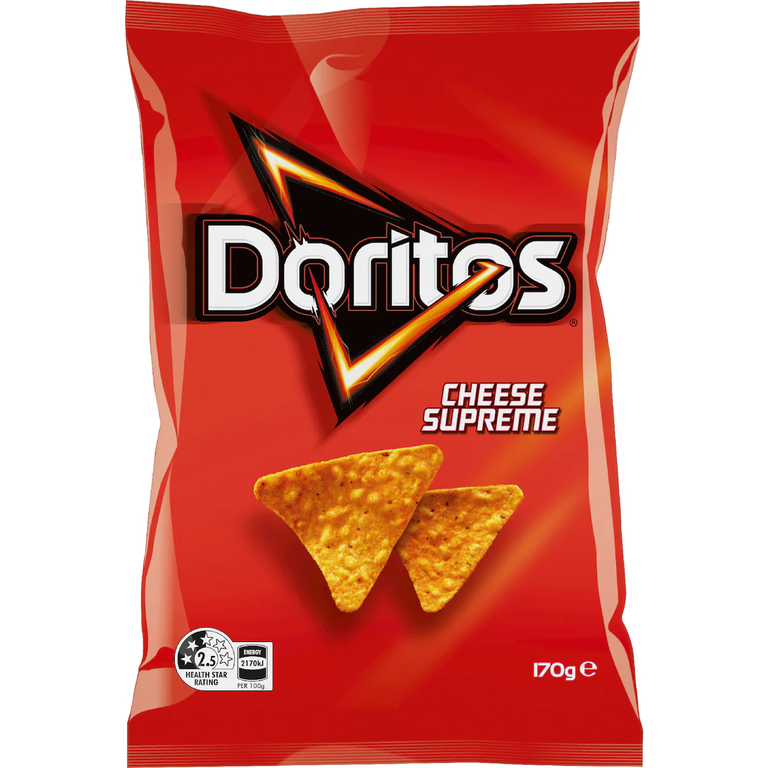

In [4]:
from google.colab import files
from PIL import Image, ImageOps
from IPython.display import display
import io

uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Please upload exactly one product photo.")

filename, image_bytes = next(iter(uploaded.items()))

# Correct phone-camera orientation and preserve the original.
original_image = ImageOps.exif_transpose(
    Image.open(io.BytesIO(image_bytes))
).convert("RGB")

(ROOT / "inputs").mkdir(parents=True, exist_ok=True)
original_image.save(ROOT / "inputs" / "pilot_original.png")

# Preserve proportions and pad to a square for the pilot.
pilot_image = ImageOps.pad(
    original_image,
    (768, 768),
    method=Image.Resampling.LANCZOS,
    color="white",
)
pilot_image.save(ROOT / "inputs" / "pilot_input.png")

print("Uploaded:", filename)
print("Original size:", original_image.size)
print("Pilot size:", pilot_image.size)
display(pilot_image)

Editable background: 64.2%


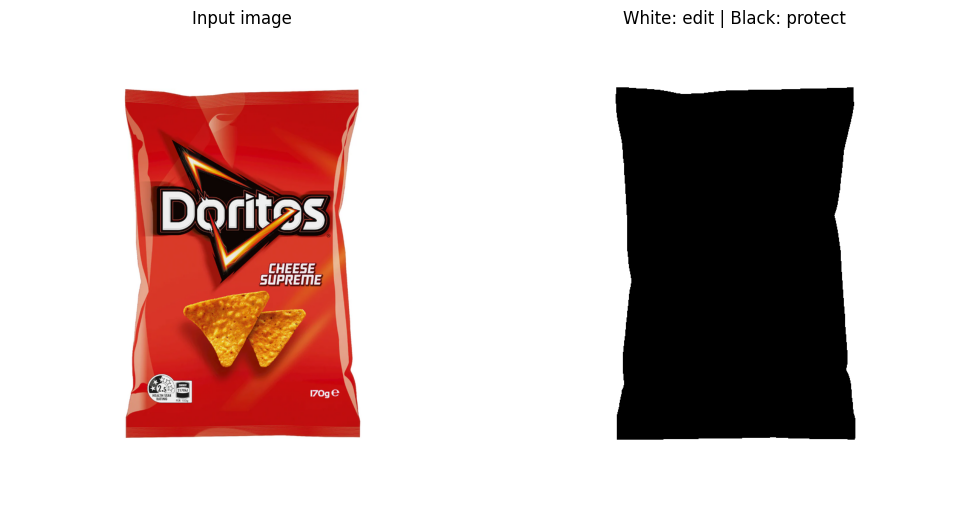

In [6]:
from collections import deque
import numpy as np
from PIL import Image, ImageOps, ImageFilter
import matplotlib.pyplot as plt

pixels = np.asarray(pilot_image.convert("RGB"))
near_white = np.all(pixels >= 240, axis=2)

height, width = near_white.shape
background = np.zeros((height, width), dtype=bool)

# Find white background connected to the canvas corner.
queue = deque([(0, 0)])
background[0, 0] = True

while queue:
    y, x = queue.popleft()

    for ny, nx in [(y-1, x), (y+1, x), (y, x-1), (y, x+1)]:
        if (
            0 <= ny < height
            and 0 <= nx < width
            and near_white[ny, nx]
            and not background[ny, nx]
        ):
            background[ny, nx] = True
            queue.append((ny, nx))

# Protect the product and a small margin around its edges.
protected_mask = Image.fromarray(
    ((~background).astype(np.uint8) * 255)
).filter(ImageFilter.MaxFilter(7))

pilot_mask = ImageOps.invert(protected_mask)

editable_fraction = np.mean(np.asarray(pilot_mask) == 255)
assert 0 < editable_fraction < 1, "Mask must contain black and white areas."

pilot_mask.save(ROOT / "masks" / "pilot_background_mask.png")

print(f"Editable background: {editable_fraction:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(pilot_image)
axes[0].set_title("Input image")
axes[1].imshow(pilot_mask, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("White: edit | Black: protect")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

  0%|          | 0/24 [00:00<?, ?it/s]

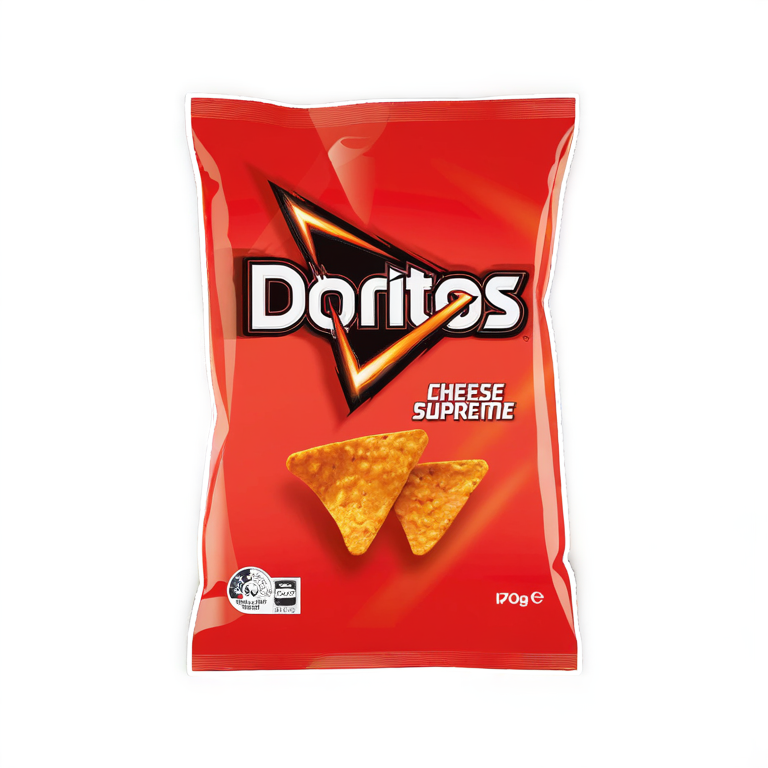

{
  "run_id": "sdxl_pilot_20261030T095401829617Z",
  "model_id": "diffusers/stable-diffusion-xl-1.0-inpainting-0.1",
  "seed": 42,
  "scheduler_class": "EulerDiscreteScheduler",
  "runtime_seconds": 50.09,
  "baseline_allocated_gpu_gb": 0.0,
  "peak_allocated_gpu_gb": 5.23,
  "peak_reserved_gpu_gb": 5.578,
  "protected_region_mae_0_to_255": 15.8491,
  "input_file": "inputs/pilot_input.png",
  "mask_file": "masks/pilot_background_mask.png",
  "output_file": "outputs/sdxl_pilot_20261030T095401829617Z.png",
  "note": "First pilot run; includes first-inference overhead."
}


In [7]:
import time
import json
import numpy as np
from datetime import datetime, timezone
from IPython.display import display

seed = 42

prompt = (
    "Commercial product photography of a single snack packet standing "
    "on a clean matte countertop, with a deep blue studio background, "
    "soft studio lighting and a realistic contact shadow, "
    "minimal composition, no additional objects."
)

negative_prompt = (
    "extra packets, duplicate products, people, hands, "
    "watermark, added text, clutter, blurry"
)

run_id = datetime.now(timezone.utc).strftime("sdxl_pilot_%Y%m%dT%H%M%S%fZ")

settings = {
    "prompt": prompt,
    "negative_prompt": negative_prompt,
    "width": 768,
    "height": 768,
    "num_inference_steps": 25,
    "guidance_scale": 7.5,
    "strength": 0.99,
}

# Record GPU memory already allocated before inference.
torch.cuda.synchronize()
baseline_memory = torch.cuda.memory_allocated()
torch.cuda.reset_peak_memory_stats()

start = time.perf_counter()

with torch.inference_mode():
    output_a = pipe_a(
        image=pilot_image,
        mask_image=pilot_mask,
        generator=torch.Generator(device="cpu").manual_seed(seed),
        **settings,
    ).images[0]

torch.cuda.synchronize()
runtime = time.perf_counter() - start

output_path = ROOT / "outputs" / f"{run_id}.png"
output_a.save(output_path)

# Measure changes in the protected region of the RAW output.
# No original product pixels are pasted back.
original_pixels = np.asarray(pilot_image, dtype=np.float32)
output_pixels = np.asarray(output_a, dtype=np.float32)
protected_region = np.asarray(pilot_mask) == 0

protected_mae = float(
    np.abs(output_pixels - original_pixels)[protected_region].mean()
)

record = {
    "run_id": run_id,
    "model_id": MODEL_A_ID,
    "seed": seed,
    "settings": settings,
    "scheduler_class": type(pipe_a.scheduler).__name__,
    "scheduler_config": dict(pipe_a.scheduler.config),
    "runtime_seconds": round(runtime, 2),
    "baseline_allocated_gpu_gb": round(baseline_memory / 1024**3, 3),
    "peak_allocated_gpu_gb": round(
        torch.cuda.max_memory_allocated() / 1024**3, 3
    ),
    "peak_reserved_gpu_gb": round(
        torch.cuda.max_memory_reserved() / 1024**3, 3
    ),
    "protected_region_mae_0_to_255": round(protected_mae, 4),
    "input_file": "inputs/pilot_input.png",
    "mask_file": "masks/pilot_background_mask.png",
    "output_file": f"outputs/{run_id}.png",
    "note": "First pilot run; includes first-inference overhead.",
}

(ROOT / "results" / f"{run_id}.json").write_text(
    json.dumps(record, indent=2, default=str)
)

display(output_a)
print(json.dumps(
    {k: v for k, v in record.items()
     if k not in ["settings", "scheduler_config"]},
    indent=2
))

Pipeline: StableDiffusionXLInpaintPipeline
U-Net input channels: 9
Input size: (768, 768)
Mask size: (768, 768)
Mask values: [  0 255]
Processed mask shape: (1, 1, 768, 768)
Processed mask minimum: 0.0
Processed mask maximum: 1.0
Processed editable fraction: 0.6417762041091919


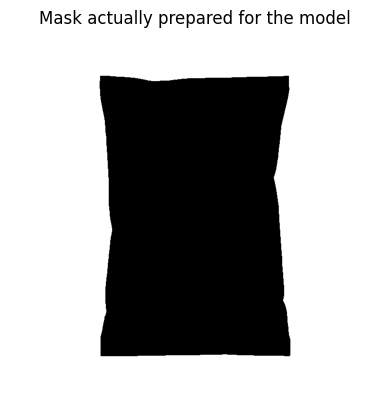

In [9]:
import numpy as np

print("Pipeline:", type(pipe_a).__name__)
print("U-Net input channels:", pipe_a.unet.config.in_channels)
print("Input size:", pilot_image.size)
print("Mask size:", pilot_mask.size)
print("Mask values:", np.unique(np.asarray(pilot_mask)))

processed_mask = pipe_a.mask_processor.preprocess(
    pilot_mask,
    height=768,
    width=768,
)

print("Processed mask shape:", tuple(processed_mask.shape))
print("Processed mask minimum:", processed_mask.min().item())
print("Processed mask maximum:", processed_mask.max().item())
print(
    "Processed editable fraction:",
    (processed_mask > 0.5).float().mean().item()
)

plt.imshow(processed_mask[0, 0].cpu().numpy(),
           cmap="gray", vmin=0, vmax=1)
plt.title("Mask actually prepared for the model")
plt.axis("off")
plt.show()